TP1_Pretraitement_ML

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

from sklearn.preprocessing import MinMaxScaler, StandardScaler

import os
os.chdir(r"C:\Users\horma\Downloads\TP1_ML")
print(os.getcwd())

df=pd.read_csv("train.csv")

C:\Users\horma\Downloads\TP1_ML


In [4]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

In [16]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [17]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [18]:
df.isnull().sum()[df.isnull().sum() > 0]

Age         177
Cabin       687
Embarked      2
dtype: int64

In [19]:
df['Age'] = df['Age'].fillna(df['Age'].median())

In [20]:
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [21]:
(df.isnull().sum() / len(df)) * 100

PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age             0.000000
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.000000
dtype: float64

In [22]:
df = df.drop(columns=['Cabin'])

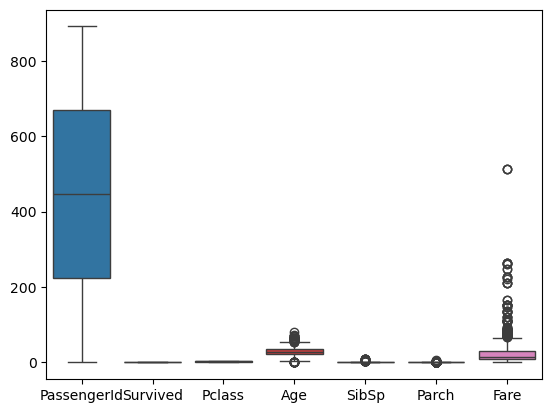

In [23]:
sns.boxplot(data=df.select_dtypes(include='number'))
plt.show()

In [24]:
for col in ['Age', 'SibSp', 'Parch', 'Fare']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_inf = Q1 - 1.5 * IQR
    limite_sup = Q3 + 1.5 * IQR

    mediane = df[col].median()

    df.loc[(df[col] < limite_inf) | (df[col] > limite_sup), col] = mediane

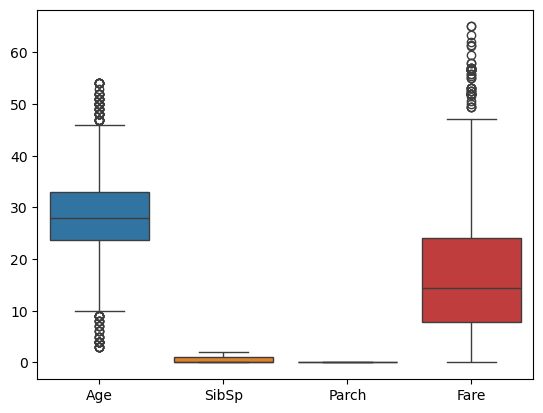

In [25]:
sns.boxplot(data=df[['Age', 'SibSp', 'Parch', 'Fare']])
plt.show()

In [26]:
df.select_dtypes(include='object').columns

Index(['Name', 'Sex', 'Ticket', 'Embarked'], dtype='object')

In [27]:
df[['Sex', 'Embarked']].nunique()

Sex         2
Embarked    3
dtype: int64

In [28]:
df = pd.get_dummies(df, columns=['Sex', 'Embarked'], drop_first=True)

In [29]:
df.head()

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Sex_male,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,True,False,True
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,14.4542,False,False,False
2,3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,False,False,True
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,False,False,True
4,5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,True,False,True


In [30]:
df['Pclass'].unique()

array([3, 1, 2])

In [31]:
df.select_dtypes(include='number').columns

Index(['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare'], dtype='object')

In [32]:
df_num = df[['Age', 'SibSp', 'Parch', 'Fare']].copy()

In [33]:
scaler = MinMaxScaler()
df_normalized = scaler.fit_transform(df_num)

In [34]:
df_normalized = pd.DataFrame(df_normalized, columns=df_num.columns)

In [35]:
df_normalized.head()

,Age,SibSp,Parch,Fare
0,0.372549,0.5,0.0,0.111538
1,0.686275,0.5,0.0,0.222372
2,0.450980,0.0,0.0,0.121923
3,0.627451,0.5,0.0,0.816923
4,0.627451,0.0,0.0,0.123846


In [36]:
scaler_std = StandardScaler()
df_standardized = scaler_std.fit_transform(df_num)

In [37]:
df_standardized = pd.DataFrame(df_standardized, columns=df_num.columns)

In [38]:
df_standardized.head()

,Age,SibSp,Parch,Fare
0,-0.661724,1.347605,0.0,-0.797554
1,0.972921,1.347605,0.0,-0.230556
2,-0.253063,-0.570472,0.0,-0.744429
3,0.666425,1.347605,0.0,2.811012
4,0.666425,-0.570472,0.0,-0.734591


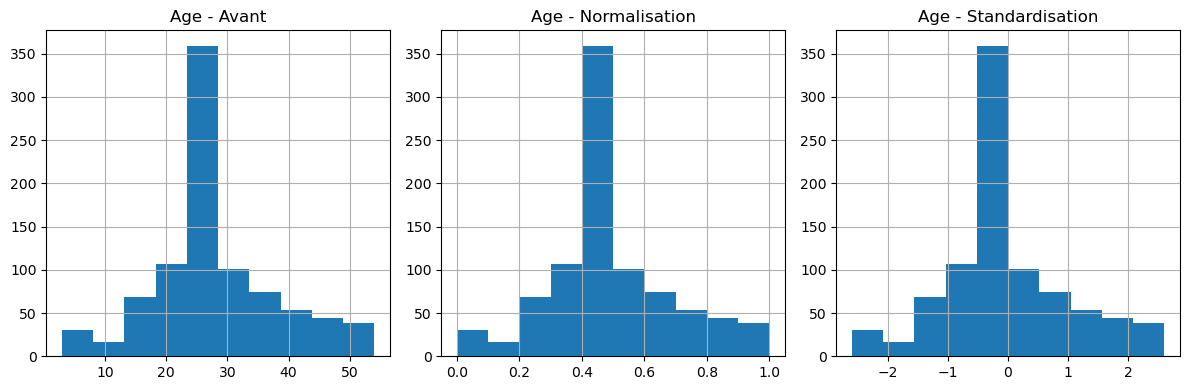

In [39]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
df_num['Age'].hist()
plt.title('Age - Avant')

plt.subplot(1, 3, 2)
df_normalized['Age'].hist()
plt.title('Age - Normalisation')

plt.subplot(1, 3, 3)
df_standardized['Age'].hist()
plt.title('Age - Standardisation')

plt.tight_layout()
plt.show()

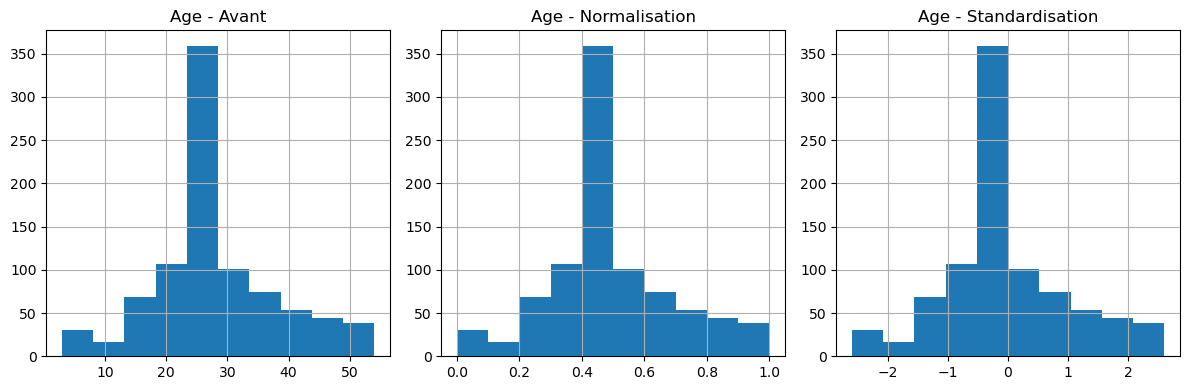

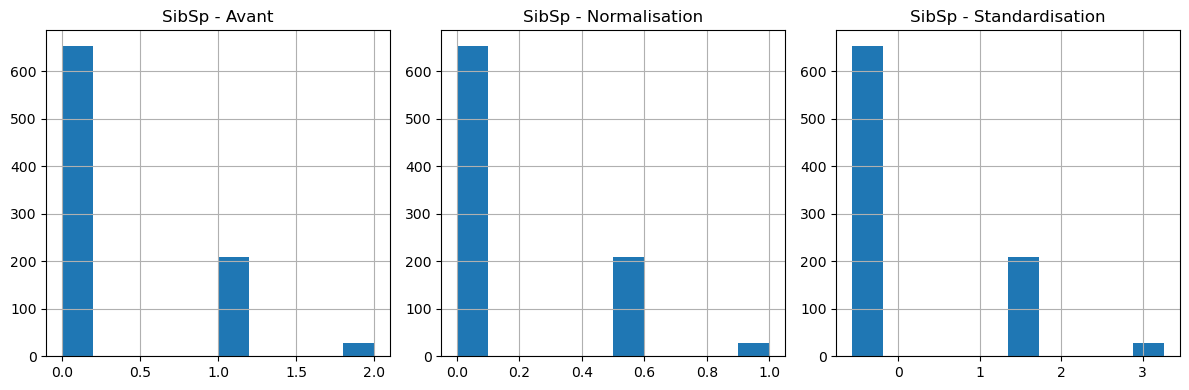

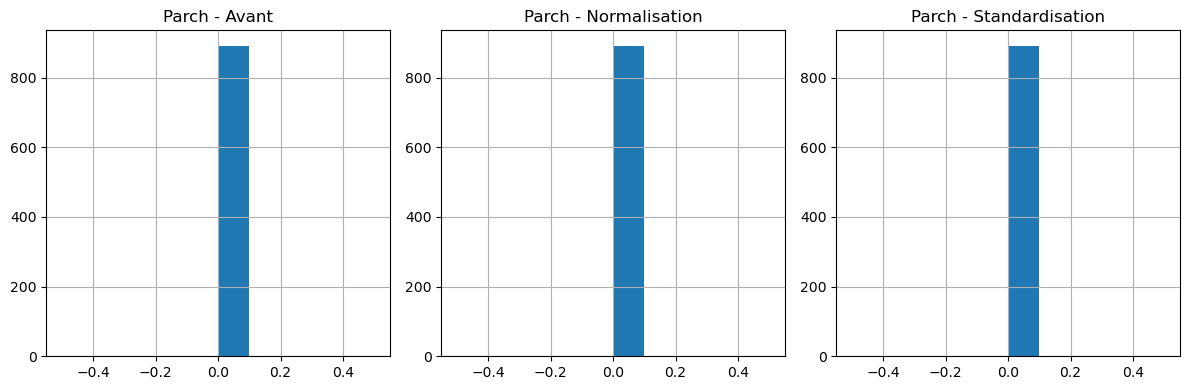

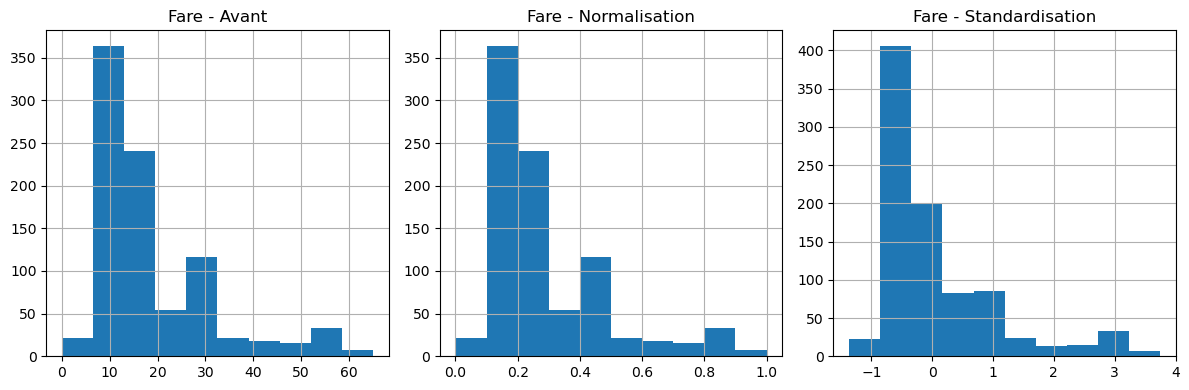

In [40]:
for col in df_num.columns:
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    df_num[col].hist()
    plt.title(col + ' - Avant')

    plt.subplot(1, 3, 2)
    df_normalized[col].hist()
    plt.title(col + ' - Normalisation')

    plt.subplot(1, 3, 3)
    df_standardized[col].hist()
    plt.title(col + ' - Standardisation')

    plt.tight_layout()
    plt.show()

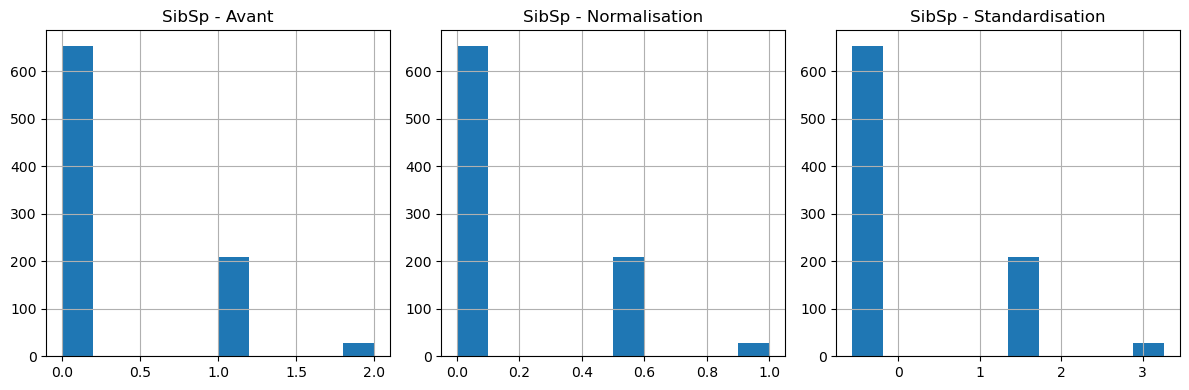

In [41]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
df_num['SibSp'].hist()
plt.title('SibSp - Avant')

plt.subplot(1, 3, 2)
df_normalized['SibSp'].hist()
plt.title('SibSp - Normalisation')

plt.subplot(1, 3, 3)
df_standardized['SibSp'].hist()
plt.title('SibSp - Standardisation')

plt.tight_layout()
plt.show()

In [42]:
df['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [43]:
from sklearn.utils import resample

df_majority = df[df['Survived'] == 0]
df_minority = df[df['Survived'] == 1]

df_majority_downsampled = resample(
    df_majority,
    replace=False,
    n_samples=len(df_minority),
    random_state=42
)

df_under = pd.concat([df_majority_downsampled, df_minority])

In [44]:
df_under['Survived'].value_counts()

Survived
0    342
1    342
Name: count, dtype: int64

In [45]:
X = df.drop('Survived', axis=1)
y = df['Survived']

In [46]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

X = df.drop('Survived', axis=1).select_dtypes(include='number')
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print(y_train_smote.value_counts())

Survived
1    439
0    439
Name: count, dtype: int64
